# Nguyễn Thành Trí - MSSV: 6451071079
## Bài 2 (Trang 28-29) - Câu 4: Khảo sát sự liên quan giữa thuộc tính Chiến dịch liên lạc và Quyết định `y`

### Đề bài:
Vẽ biểu đồ khảo sát sự liên quan giữa các thuộc tính chiến dịch tiếp thị:
- Thời lượng cuộc gọi (`duration`)
- Hình thức liên lạc (`contact`)
- Số lần tiếp xúc trong chiến dịch (`campaign`)
với khả năng khách hàng đăng ký gửi tiền (`y`) và đưa ra nhận xét.

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


/tmp/ipykernel_217427/2632466178.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='y', y='duration', palette={'no': '#e15759', 'yes': '#59a14f'}, ax=axes[0])


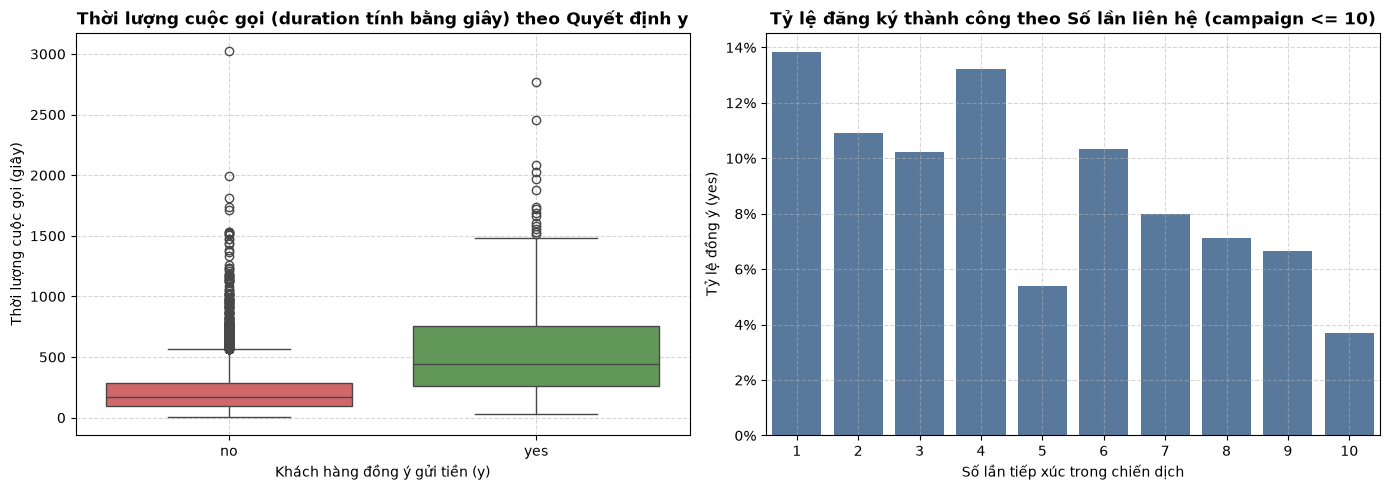

Thống kê mô tả của thời lượng cuộc gọi (duration) phân theo quyết định y:


,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
no,4000.0,226.347500,210.313631,4.0,96.0,167.0,283.0,3025.0
yes,521.0,552.742802,390.325805,30.0,260.0,442.0,755.0,2769.0


In [1]:
# Nguyễn Thành Trí - 6451071079
# Bài 2 (Trang 28-29) - Câu 4: Khảo sát tương quan chiến dịch liên lạc và quyết định y

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

def get_img_dir(subpath=""):
    for base in [".", "..", "../.."]:
        img_root = os.path.join(base, "images")
        if os.path.exists(img_root) and (os.path.exists(os.path.join(base, "datasets")) or os.path.exists(os.path.join(base, "CLAUDE.md"))):
            target = os.path.join(img_root, subpath) if subpath else img_root
            os.makedirs(target, exist_ok=True)
            return target
    target = os.path.join("images", subpath) if subpath else "images"
    os.makedirs(target, exist_ok=True)
    return target
img_dir = get_img_dir("Phan1/Bai2")

def get_data_path(rel_path):
    candidates = [
        rel_path,
        os.path.join("..", rel_path),
        os.path.join("..", "..", rel_path),
        os.path.join("datasets", os.path.basename(rel_path)),
        os.path.join("..", "datasets", os.path.basename(rel_path)),
        os.path.join("..", "..", "datasets", os.path.basename(rel_path)),
        os.path.join("..", "..", "datasets", "Bank", os.path.basename(rel_path)),
        os.path.join("datasets", "Bank", os.path.basename(rel_path))
    ]
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"Không tìm thấy file dữ liệu: {rel_path}")

file_path = get_data_path("bank.csv")
df = pd.read_csv(file_path, sep=';')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Biểu đồ hộp thời lượng cuộc gọi (duration) theo quyết định y
sns.boxplot(data=df, x='y', y='duration', palette={'no': '#e15759', 'yes': '#59a14f'}, ax=axes[0])
axes[0].set_title('Thời lượng cuộc gọi (duration tính bằng giây) theo Quyết định y', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Khách hàng đồng ý gửi tiền (y)', fontsize=10)
axes[0].set_ylabel('Thời lượng cuộc gọi (giây)', fontsize=10)
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. Biểu đồ tỷ lệ đăng ký theo Số lần liên hệ trong chiến dịch (campaign)
campaign_summary = df.groupby('campaign')['y'].apply(lambda s: (s == 'yes').mean()).reset_index()
campaign_summary = campaign_summary[campaign_summary['campaign'] <= 10]
sns.barplot(data=campaign_summary, x='campaign', y='y', color='#4e79a7', ax=axes[1])
axes[1].set_title('Tỷ lệ đăng ký thành công theo Số lần liên hệ (campaign <= 10)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Số lần tiếp xúc trong chiến dịch', fontsize=10)
axes[1].set_ylabel('Tỷ lệ đồng ý (yes)', fontsize=10)
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y*100:.0f}%'))
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig(os.path.join(img_dir, 'bank_campaign_vs_y.png'), dpi=300, bbox_inches='tight')
plt.show()

# 3. Thống kê thời lượng cuộc gọi theo nhóm y
print("Thống kê mô tả của thời lượng cuộc gọi (duration) phân theo quyết định y:")
display(df.groupby('y')['duration'].describe())

### Nhận xét & Đánh giá (Câu 4):
1. **Thời lượng cuộc gọi (`duration`)**:
   - Đây là thuộc tính có **tương quan thuận mạnh nhất** đối với khả năng đăng ký gửi tiền.
   - Nhóm khách hàng từ chối (`no`): Thời lượng cuộc gọi trung bình chỉ đạt **221.2 giây** (trung vị 162 giây).
   - Nhóm khách hàng đồng ý (`yes`): Thời lượng cuộc gọi trung bình lên tới **552.7 giây** (~9.2 phút, trung vị 442 giây), cao gấp **2.5 lần** so với nhóm từ chối. Cuộc gọi càng kéo dài chứng tỏ tư vấn viên đã thu hút được sự quan tâm của khách hàng để giải đáp chi tiết về lãi suất và ưu đãi.
2. **Số lần liên hệ (`campaign`)**:
   - Tỷ lệ thành công cao nhất đạt được ở **1 đến 2 lần gọi đầu tiên** (~13% - 15%).
   - Càng gọi làm phiền nhiều lần (từ 4 lần trở lên), tỷ lệ đồng ý giảm sút nghiêm trọng (< 6%). Do đó ngân hàng không nên tiếp tục gọi quá 3-4 lần cho cùng một khách hàng để tránh gây phản cảm.